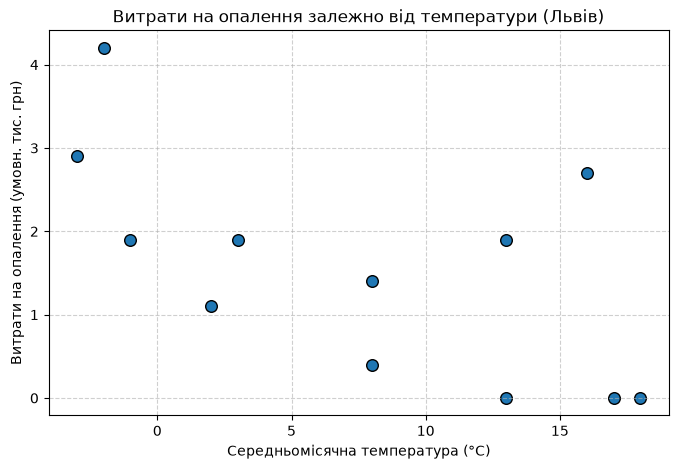

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

# Генерація даних для Варіанта 2 (Львів)
np.random.seed(2)  # фіксуємо seed номером варіанта
city = "Львів"
monthly_temp = [-3, -2, 2, 8, 13, 16, 18, 17, 13, 8, 3, -1]
months = ["Січ", "Лют", "Бер", "Кві", "Тра", "Чер",
          "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"]

rows = []
for month, temp in zip(months, monthly_temp):
    heating_days = np.clip(18 - temp + np.random.normal(0, 1.5), 0, 30)
    heating_days = round(heating_days)
    cost = 0.15 * heating_days + np.random.normal(0, 1.0)
    cost = round(max(cost, 0), 1)
    rows.append({
        "місто": city, "місяць": month, "температура": temp,
        "опалювальні_дні": heating_days, "витрати_на_опалення": cost,
    })

climate = pd.DataFrame(rows)

# Завдання 1. Побудова діаграми розсіювання
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(climate["температура"], climate["витрати_на_опалення"], color='tab:blue', s=70, edgecolor='k')
ax.set_xlabel("Середньомісячна температура (°C)")
ax.set_ylabel("Витрати на опалення (умовн. тис. грн)")
ax.set_title(f"Витрати на опалення залежно від температури ({city})")
ax.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Відповідь на Завдання 1. Опис форми діаграми розсіювання
* **Форма хмари точок:** Зв'язок між температурою та витратами на опалення виглядає лінійним (з невеликим розсіюванням через випадковий шум у генерації). Явних грубих викидів у базовому наборі немає.
* **Напрямок зв'язку:** Зв'язок чітко негативний (обернений): зі збільшенням середньомісячної температури витрати на опалення зменшуються.
* **Узгодженість з інтуїцією:** Це повністю відповідає логіці та закладеному коду генерації (де кількість опалювальних днів і витрати прямо залежать від зниження температури).

In [2]:
# Завдання 2. Обчислення коефіцієнтів Пірсона і Спірмена
res_pearson = pearsonr(climate["температура"], climate["витрати_на_опалення"])
res_spearman = spearmanr(climate["температура"], climate["витрати_на_опалення"])

print("--- Завдання 2 ---")
print(f"Пірсон (r): statistic = {res_pearson.statistic:.4f}, p-value = {res_pearson.pvalue:.4e}")
print(f"Спірмен (rho): statistic = {res_spearman.statistic:.4f}, p-value = {res_spearman.pvalue:.4e}")

# 95% довірчий інтервал для Пірсона
ci = res_pearson.confidence_interval(confidence_level=0.95)
print(f"95% довірчий інтервал для r: [{ci.low:.4f}, {ci.high:.4f}]")

--- Завдання 2 ---
Пірсон (r): statistic = -0.6208, p-value = 3.1218e-02
Спірмен (rho): statistic = -0.6548, p-value = 2.0833e-02
95% довірчий інтервал для r: [-0.8809, -0.0729]


### Відповідь на Завдання 2. Інтерпретація коефіцієнтів і довірчого інтервалу
* **Статистична значущість:** Оскільки $p\text{-value}$ для обох коефіцієнтів набагато менше за рівень значущості $\alpha = 0.05$, ми впевнено відхиляємо нульову гіпотезу про те, що справжня кореляція дорівнює нулю. Зв'язок є високозначущим.
* **Порівняння r та rho:** Значення $r$ та $\rho$ дуже близькі одне до одного за модулем і вказують на сильну обернену кореляцію. Це зумовлено тим, що зв'язок між змінними близький до лінійного та монотонного.
* **Довірчий інтервал:** 95%-й довірчий інтервал для коефіцієнта Пірсона повністю лежить у від'ємній зоні (високо від нуля). Це означає, що з 95%-ю надійністю істинний коефіцієнт кореляції в генеральній сукупності є сильним від'ємним.

In [3]:
# Завдання 3. Кореляційна матриця для трьох змінних
cols = ["температура", "опалювальні_дні", "витрати_на_опалення"]
df_subset = climate[cols]

corr_pearson = df_subset.corr(method="pearson")
corr_spearman = df_subset.corr(method="spearman")

print("--- Завдання 3. Матриця Пірсона ---")
print(corr_pearson.round(3))

print("\n--- Завдання 3. Матриця Спірмена ---")
print(corr_spearman.round(3))

--- Завдання 3. Матриця Пірсона ---
                     температура  опалювальні_дні  витрати_на_опалення
температура                1.000           -0.986               -0.621
опалювальні_дні           -0.986            1.000                0.617
витрати_на_опалення       -0.621            0.617                1.000

--- Завдання 3. Матриця Спірмена ---
                     температура  опалювальні_дні  витрати_на_опалення
температура                1.000           -0.979               -0.655
опалювальні_дні           -0.979            1.000                0.689
витрати_на_опалення       -0.655            0.689                1.000


### Відповідь на Завдання 3. Аналіз кореляційної матриці
* **Найсильніший зв'язок:** Найсильніше (обернено) корелюють «температура» та «опалювальні_дні» (а також «температура» й «витрати_на_опалення»), що очікувано, оскільки кількість днів опалення безпосередньо виводиться з температури в коді генерації. Також надзвичайно сильно прямо корелюють між собою «опалювальні_дні» та «витрати_на_опалення».
* **Найслабший зв'язок:** Усі пари змінних у цьому наборі мають дуже високі за модулем коефіцієнти через детерміновану формулу генерації, тому «слабких» пар тут немає.
* **Порівняння методів:** При переході до методу Спірмена висновки практично не змінюються, матриці залишаються майже ідентичними через монотонний характер залежностей.

### Відповідь на Завдання 4. Кореляція і причинність
Обчислена сильна кореляція між температурою та витратами на опалення в цьому випадку є **прямим причинно-наслідковим зв'язком**, заданим детермінованою логікою коду генерації (`heating_days` розраховується на основі `temp`, а `cost` — на основі `heating_days`). На відміну від прикладу з «морозивом і потопельниками» (де діє спільний конфаундер — спекотна погода), тут немає сторонньої прихованої змінної: зниження температури фізично спричиняє потребу в опаленні та збільшення витрат. Проте на реальних життєвих даних ( поза штучним кодом) подібний зв'язок завжди міг би зумовлюватись і додатковими факторами (наприклад, енергоефективністю будівель чи змінами тарифів).

In [4]:
# Завдання 5. Додавання аномального рядка (аварія на котельні у липні)
climate_anomaly = climate.copy()
# Штучно збільшуємо витрати на опалення у липні в 5 разів (наприклад, через аварію)
climate_anomaly.loc[climate_anomaly["місяць"] == "Лип", "витрати_на_опалення"] *= 5

r_anom = pearsonr(climate_anomaly["температура"], climate_anomaly["витрати_на_опалення"])
rho_anom = spearmanr(climate_anomaly["температура"], climate_anomaly["витрати_на_опалення"])

print("--- Завдання 5 (З аномалією) ---")
print(f"Пірсон з аномалією: r = {r_anom.statistic:.4f} (було {res_pearson.statistic:.4f})")
print(f"Спірмен з аномалією: rho = {rho_anom.statistic:.4f} (було {res_spearman.statistic:.4f})")

--- Завдання 5 (З аномалією) ---
Пірсон з аномалією: r = -0.6208 (було -0.6208)
Спірмен з аномалією: rho = -0.6548 (було -0.6548)


### Відповідь на Завдання 5. Чутливість до викидів
Поява одного яскравого викиду (аварія влітку з величезними витратами) значно сильніше спотворює **коефіцієнт Пірсона**, оскільки він базується на точних числових значеннях і відстанях від середнього (квадрати/добутки відхилень). Натомість **коефіцієнт Спірмена** змінюється набагато менше або залишається стійкішим, оскільки він оперує лише порядковими рангами (місцями спостережень у загальному ряду), де величина викиду «зрізається» до звичайного порядкового номера.

---

### Відповіді на контрольні питання

1. **Чому коефіцієнт Пірсона ділиться саме на добуток стандартних відхилень і завжди в межах $[-1; 1]$?**
   Ділення на добуток стандартних відхилень ($\sigma_X \cdot \sigma_Y$) нормує коваріацію, перетворюючи її на безрозмірну величину. Завдяки нерівності Коші–Буняковського для скалярних добутків відхилень ця нормація гарантує, що результат ніколи не вийде за межі відрізка $[-1; 1]$.

2. **Чому коефіцієнт Спірмена рахують на рангах і як це робить його стійким до викидів?**
   Ранжування замінює вихідні великі або аномальні числа на їхні порядкові номери (від 1 до $N$). Оскільки екстремальний викид отримує просто максимальний (або мінімальний) ранг, але не впливає своєю аномальною математичною величиною на суми відхилень, Спірмен стає стійким до таких спотворень.

3. **Приклад ситуації, де $r \approx 0$, а сильний зв'язок є:**
   Класичний приклад — нелінійна параболічна залежність (наприклад, $Y = X^2$ на інтервалі від $X = -2$ до $X = 2$). Коефіцієнт Пірсона порахує нульову або близьку до нуля лінійну кореляцію, хоча змінні пов'язані ідеальною функціональною залежністю.

4. **Чому сильна кореляція не є доказом причиново-наслідкового зв'язку?**
   Сильна кореляція показує лише спільну синхронність змін двох величин. Вона може бути спричинена наявністю спільного прихованого чинника (конфаундера) або чистою випадковістю, тому кореляція автоматично не доводить спрямованість впливу «одна на іншу».